# 06 - Exploratory Data Analysis

## 1. Introduction and Research Objectives

### 1.1 Objective

The objective of this notebook is to investigate the historical price behaviour of the four financial instruments selected for the initial research universe.

The analysis aims to understand their long-term price evolution, historical patterns, price distributions and differences in market behaviour.

### 1.2 Instruments Under Analysis

The analysis covers the following instruments:

- **National Grid (NG.L)** — UK electricity and gas transmission and distribution company.
- **SSE (SSE.L)** — UK energy company.
- **Severn Trent (SVT.L)** — UK water and wastewater utility company.
- **FTSE 100 (^FTSE)** — UK equity market benchmark index.

### 1.3 Research Questions

This exploratory analysis will investigate:

1. How have the historical prices of each instrument evolved?
2. What long-term trends and historical patterns can be observed?
3. How different are the price distributions across the instruments?
4. How have the instruments behaved during different historical periods?
5. What similarities and differences can be identified between the three utility companies and the FTSE 100 benchmark?

### 1.4 Methodological Principles

- Use the previously acquired Raw datasets.
- Preserve the original source data.
- Do not apply automatic imputation or remove observations.
- Distinguish observed market behaviour from potential data limitations.
- Avoid interpreting historical price movements as evidence of future performance.
- Keep exploratory analysis separate from forecasting and trading strategy development.

### 1.5 Scope

This notebook focuses on historical price behaviour.

Returns, volatility, forecasting models, trading signals and strategy development will be addressed in their respective project phases.

## 2. Data Loading and Preparation

### 2.1 Data Sources

The analysis uses the historical market datasets previously acquired from Yahoo Finance and stored in the project's Raw data layer.

The four instruments are loaded from their respective acquisition directories. The original Parquet files are used to preserve the acquired data structure and numerical precision.

### 2.2 Data Preparation

The datasets will be loaded into individual pandas DataFrames and organised in a dictionary indexed by ticker symbol.

No transformations will be applied to the original observations at this stage.

### 2.3 Data Integrity Considerations

The data quality assessment conducted during Phase 3 identified limitations involving missing observations, zero-volume records, historical price discrepancies and corporate action information.

These findings remain documented in the Phase 3 Data Quality Assessment. They will be treated as known limitations during the interpretation of the exploratory results, without repeating the original quality assessment.

In [9]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

RAW_MARKET_DATA = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "market"
    / "yahoo_finance"
)

ACQUISITIONS = {
    "NG.L": "acquisition_20261103T000455Z_8b505769",
    "SSE.L": "acquisition_20261103T002507Z_de101edb",
    "SVT.L": "acquisition_20261103T002515Z_fdac38df",
    "^FTSE": "acquisition_20261103T002524Z_9c7eb120",
}

market_data = {}

for ticker, acquisition_id in ACQUISITIONS.items():

    file_path = (
        RAW_MARKET_DATA
        / ticker
        / acquisition_id
        / f"{ticker}.parquet"
    )

    if not file_path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {file_path}"
        )

    market_data[ticker] = pd.read_parquet(file_path)

print("Market datasets loaded successfully.")

print(f"Number of assets: {len(market_data)}")

Market datasets loaded successfully.
Number of assets: 4


In [10]:
for ticker, df in market_data.items():

    print("\n" + "=" * 70)
    print(f"ASSET: {ticker}")
    print("=" * 70)

    print(f"Shape: {df.shape}")
    print(f"Index type: {type(df.index).__name__}")
    print(f"Index name: {df.index.name}")
    print(f"Index dtype: {df.index.dtype}")

    print("\nColumns:")
    print(df.columns)

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isna().sum())

    print("\nFirst observation:")
    print(df.head(1))

    print("\nLast observation:")
    print(df.tail(1))

    print("\nDuplicate index entries:")
    print(df.index.duplicated().sum())

    print("\nDate range:")
    print(df.index.min(), "to", df.index.max())


ASSET: NG.L
Shape: (7890, 8)
Index type: DatetimeIndex
Index name: Date
Index dtype: datetime64[ms]

Columns:
Index(['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open',
       'Stock Splits', 'Volume'],
      dtype='str', name='Price')

Data types:
Price
Adj Close       float64
Close           float64
Dividends       float64
High            float64
Low             float64
Open            float64
Stock Splits    float64
Volume            int64
dtype: object

Missing values:
Price
Adj Close       1
Close           1
Dividends       0
High            0
Low             0
Open            0
Stock Splits    0
Volume          0
dtype: int64

First observation:
Price        Adj Close       Close  Dividends        High         Low  \
Date                                                                    
1995-12-11  267.393036  271.597504        0.0  271.597504  271.597504   

Price             Open  Stock Splits    Volume  
Date                                            
1995-12-11  27

## 6. Missing Data Investigation

### Objective

This section investigates missing observations in the four financial
market datasets.

The objective is to identify the dates affected by missing values,
understand the distribution of missing observations across columns,
and determine whether missing values are concentrated in specific
periods.

### Methodology

For each asset, the analysis will:

- Identify rows containing at least one missing value.
- Report the dates associated with missing observations.
- Identify which columns are affected.
- Examine whether missing values occur simultaneously across columns.
- Distinguish isolated missing values from broader data gaps.

### Data Handling Policy

No observations will be deleted or imputed.

The original Raw datasets will remain unchanged.

Any proposed treatment will be documented separately and will require
methodological justification.

### Research Considerations

Missing closing prices can affect return calculations.

Missing OHLC observations may affect historical price analysis.

The interpretation of missing trading volume must also account for
the distinction between individual equities and market indices.

In [11]:
# Import the libraries required for data loading and initial inspection.

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Define the project root directory.
# This assumes that the notebook is executed from the repository root.

PROJECT_ROOT = Path.cwd()


# Define the location of the original Yahoo Finance datasets.

RAW_MARKET_DATA = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "market"
    / "yahoo_finance"
)


# Map each instrument to its original acquisition directory.
# These acquisition identifiers preserve the provenance of the datasets.

ACQUISITIONS = {
    "NG.L": "acquisition_20261103T000455Z_8b505769",
    "SSE.L": "acquisition_20261103T002507Z_de101edb",
    "SVT.L": "acquisition_20261103T002515Z_fdac38df",
    "^FTSE": "acquisition_20261103T002524Z_9c7eb120",
}


# Load each instrument into an individual pandas DataFrame.
# The original Raw files are read without modifying their contents.

market_data = {}

for ticker, acquisition_id in ACQUISITIONS.items():

    file_path = (
        RAW_MARKET_DATA
        / ticker
        / acquisition_id
        / f"{ticker}.parquet"
    )

    # Stop execution if an expected source file is unavailable.
    if not file_path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {file_path}"
        )

    # Read the original Parquet dataset.
    market_data[ticker] = pd.read_parquet(file_path)


# Confirm that all four instruments have been loaded.

print("Market datasets loaded successfully.")
print(f"Number of instruments: {len(market_data)}")
print(f"Instruments: {list(market_data.keys())}")

Market datasets loaded successfully.
Number of instruments: 4
Instruments: ['NG.L', 'SSE.L', 'SVT.L', '^FTSE']


### 2.4 Dataset Structure Overview

Before analysing historical price behaviour, it is important to understand the structure and temporal coverage of each dataset.

This section examines:

- Number of observations.
- Historical starting and ending dates.
- Available variables.
- Data types.

The purpose is to establish the analytical scope and identify the historical coverage available for each instrument.

This is a structural overview only. The detailed data quality assessment was already conducted during Phase 3.

In [12]:
# Create a structural overview of the four financial instruments.
# This provides the observation count, historical coverage,
# available columns and data types for each dataset.

for ticker, df in market_data.items():

    print(f"\n{'=' * 60}")
    print(f"Instrument: {ticker}")
    print(f"{'=' * 60}")

    # Display the dataset dimensions.
    print(f"Number of observations: {df.shape[0]}")
    print(f"Number of variables: {df.shape[1]}")

    # Display the historical date range.
    print(f"First observation: {df.index.min().date()}")
    print(f"Last observation: {df.index.max().date()}")

    # Display the available variables.
    print("\nAvailable columns:")
    print(list(df.columns))

    # Display the data types.
    print("\nData types:")
    print(df.dtypes)


Instrument: NG.L
Number of observations: 7890
Number of variables: 8
First observation: 1995-12-11
Last observation: 2026-11-02

Available columns:
['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']

Data types:
Price
Adj Close       float64
Close           float64
Dividends       float64
High            float64
Low             float64
Open            float64
Stock Splits    float64
Volume            int64
dtype: object

Instrument: SSE.L
Number of observations: 9060
Number of variables: 8
First observation: 1991-06-17
Last observation: 2026-11-02

Available columns:
['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']

Data types:
Price
Adj Close       float64
Close           float64
Dividends       float64
High            float64
Low             float64
Open            float64
Stock Splits    float64
Volume            int64
dtype: object

Instrument: SVT.L
Number of observations: 9455
Number of variables: 8
First obse

## 3. Historical Price Evolution

### 3.1 Historical Price Behaviour

The first stage of the analysis examines the historical closing price evolution of each instrument.

Historical price charts provide an initial understanding of:

- Long-term price trends.
- Major historical price movements.
- Periods of relative stability or substantial price changes.
- Differences in historical behaviour between the three utility companies and the FTSE 100 benchmark.

Each instrument will initially be examined independently because their nominal price levels and historical coverage differ.

The analysis uses the `Close` variable rather than `Adj Close`. This allows us to examine the historical closing prices as reported by the data provider, without incorporating its dividend and corporate-action adjustments into the initial visualisation.

The charts are exploratory. Observed movements do not, by themselves, establish their underlying economic causes.

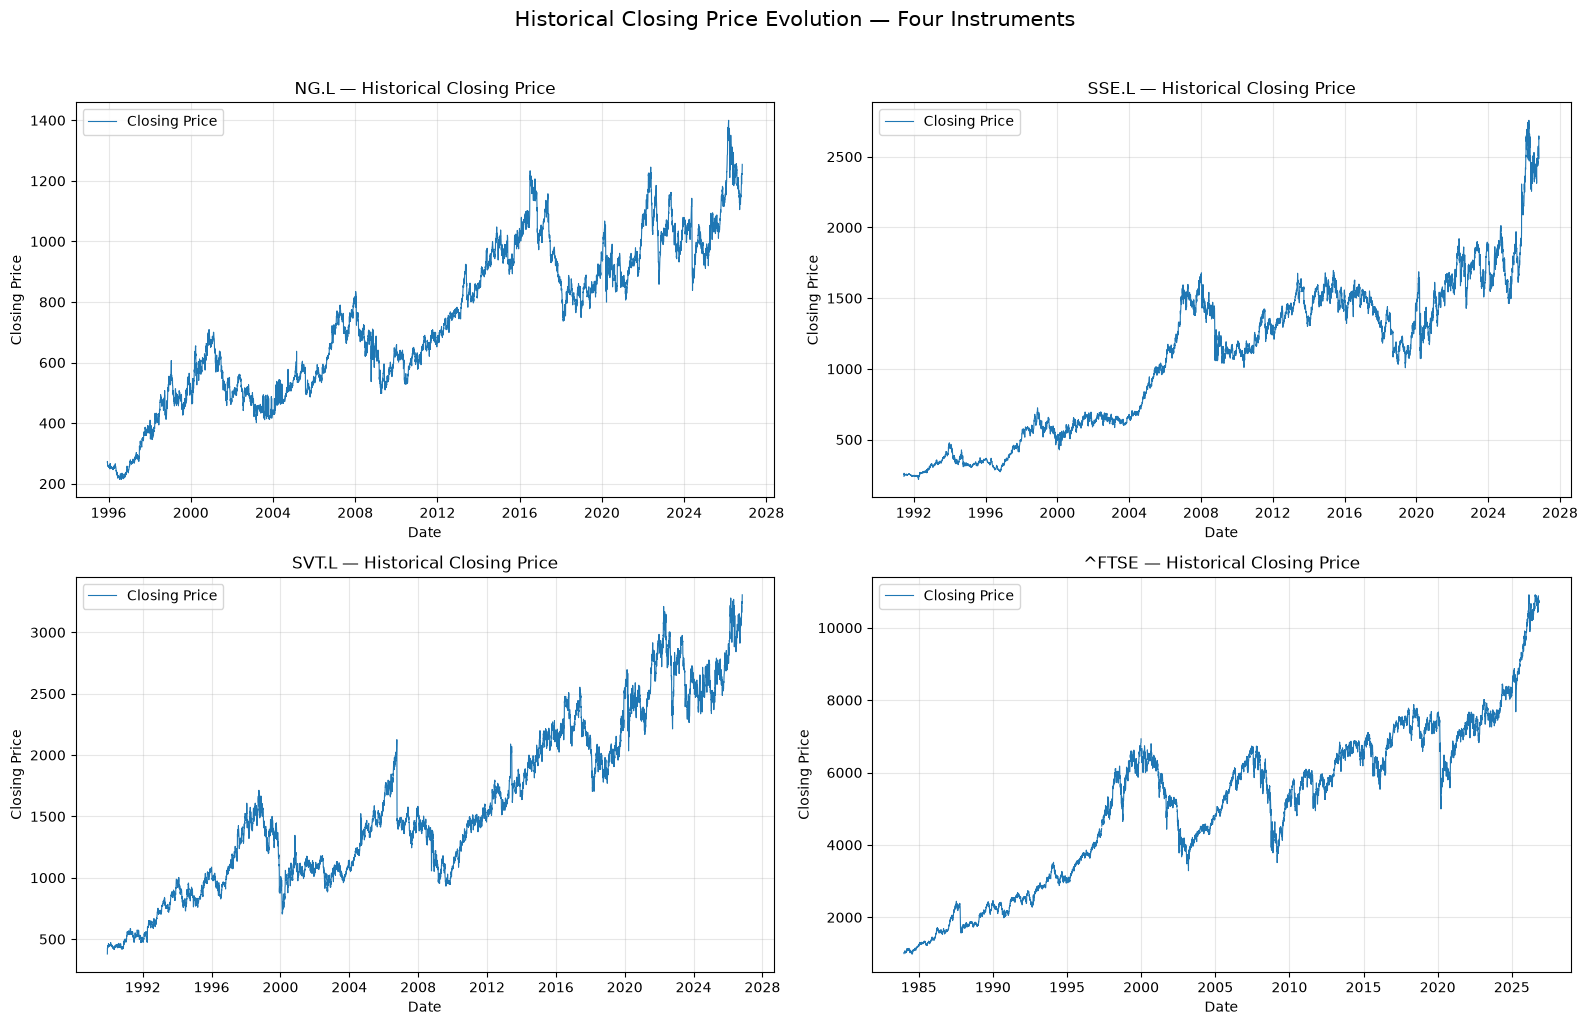

In [13]:
# Create a 2x2 layout to examine the historical closing prices
# of the four instruments independently.

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(16, 10)
)

# Define the order in which the instruments will be displayed.
tickers = ["NG.L", "SSE.L", "SVT.L", "^FTSE"]

# Add a separate historical price chart for each instrument.
for ticker, ax in zip(tickers, axes.flatten()):

    # Retrieve the original dataset for the current instrument.
    df = market_data[ticker]

    # Plot the historical closing price.
    # Missing observations are preserved and are not imputed.
    ax.plot(
        df.index,
        df["Close"],
        linewidth=0.8,
        label="Closing Price"
    )

    # Add chart title and axis labels.
    ax.set_title(
        f"{ticker} — Historical Closing Price",
        fontsize=12
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Closing Price")

    # Improve readability with grid lines.
    ax.grid(
        True,
        alpha=0.3
    )

    # Display the legend.
    ax.legend()


# Add an overall title to the figure.
fig.suptitle(
    "Historical Closing Price Evolution — Four Instruments",
    fontsize=15,
    y=1.02
)

# Adjust spacing between charts.
plt.tight_layout()

# Display the four historical price charts.
plt.show()

### 3.2 Initial Historical Price Observations

The historical closing price charts reveal an overall upward long-term trajectory across the three utility companies and the FTSE 100 index.

However, their historical paths differ considerably.

**National Grid (NG.L)**

National Grid displays a generally upward long-term price trajectory, interrupted by several substantial corrections. Notable periods of price movement include the early 2000s, the 2008–2009 financial crisis and the period following 2016.

**SSE (SSE.L)**

SSE exhibits relatively subdued price movements during its earlier historical period, followed by a substantial appreciation between 2004 and 2008. The subsequent period includes a significant correction, an extended period of fluctuations and a strong upward movement from approximately 2020 onwards.

**Severn Trent (SVT.L)**

Severn Trent also displays an upward long-term trajectory, although its historical price series contains several pronounced corrections and abrupt movements. These observations require cautious interpretation, particularly in light of the historical data limitations identified during Phase 3.

**FTSE 100 (^FTSE)**

The FTSE 100 exhibits a broad upward long-term trajectory, interrupted by substantial market corrections, particularly during 2000–2003, 2008–2009 and 2020.

### Preliminary Comparative Observations

Although all four instruments display an overall upward long-term trajectory, the magnitude, timing and apparent irregularity of their price movements differ.

These visual observations are descriptive rather than statistical. They do not establish the causes of historical price movements or demonstrate differences in investment performance.

Further descriptive analysis is required before drawing stronger conclusions.

### 3.3 Descriptive Statistics of Historical Prices

This section examines the statistical distribution of historical closing prices for each instrument.

The following descriptive statistics will be calculated:

- Number of valid observations.
- Mean and median.
- Standard deviation.
- Minimum and maximum values.
- First and third quartiles.

These statistics provide an overview of the central tendency, dispersion and historical range of each price series.

The analysis uses the `Close` variable and excludes missing values from individual calculations through pandas' default behaviour.

**Interpretation limitations:**

- Historical price levels are not directly comparable across instruments because their nominal scales and quotation conventions may differ.
- The mean and standard deviation are sensitive to long-term price trends.
- These statistics describe historical price levels, not investment returns or risk-adjusted performance.

The results will therefore be interpreted separately for each instrument.

In [14]:
# Calculate descriptive statistics for the historical closing prices.
# Each instrument is analysed independently to preserve its original
# price scale and historical observations.

descriptive_statistics = {}

for ticker, df in market_data.items():

    # Select the closing price series.
    closing_prices = df["Close"]

    # Calculate the required descriptive statistics.
    statistics = {
        "Observations": closing_prices.count(),
        "Mean": closing_prices.mean(),
        "Median": closing_prices.median(),
        "Standard Deviation": closing_prices.std(),
        "Minimum": closing_prices.min(),
        "25th Percentile": closing_prices.quantile(0.25),
        "75th Percentile": closing_prices.quantile(0.75),
        "Maximum": closing_prices.max(),
    }

    # Store the results for the current instrument.
    descriptive_statistics[ticker] = statistics


# Organise the results into a single DataFrame.
# Instruments are displayed in rows and statistics in columns.

price_statistics_df = pd.DataFrame(
    descriptive_statistics
).T


# Display the descriptive statistics.
display(
    price_statistics_df.round(2)
)

,Observations,Mean,Median,Standard Deviation,Minimum,25th Percentile,75th Percentile,Maximum
NG.L,7889.0,734.34,707.37,253.72,213.91,530.89,946.30,1400.0
SSE.L,9059.0,1076.16,1157.50,541.38,218.00,589.00,1499.50,2757.5
SVT.L,9454.0,1578.29,1446.50,692.20,378.95,1037.37,2130.00,3306.0
^FTSE,10820.0,5109.03,5537.80,2199.70,986.90,3135.70,6674.73,10910.6


### 3.3.1 Interpretation of Descriptive Statistics

The descriptive statistics provide an initial quantitative overview of the historical closing price distributions.

**National Grid (NG.L)**

The mean closing price is 734.34, compared with a median of 707.37. The historical price observations range from 213.91 to 1,400.00. The upper half of the distribution extends considerably beyond the lower half, suggesting an influence from higher historical price levels.

**SSE (SSE.L)**

The mean closing price is 1,076.16, below the median of 1,157.50. The observed range extends from 218.00 to 2,757.50. The difference between the mean and median indicates that relatively low historical price observations influence the overall distribution.

**Severn Trent (SVT.L)**

The mean closing price is 1,578.29, compared with a median of 1,446.50. The historical range extends from 378.95 to 3,306.00. The difference between the mean and median suggests an influence from higher price observations.

**FTSE 100 (^FTSE)**

The mean index level is 5,109.03 points, while the median is 5,537.80 points. The observed range extends from 986.90 to 10,910.60 points, reflecting the substantial variation in index levels over the historical sample.

### Comparative Interpretation

The four instruments exhibit different historical price distributions and nominal scales.

The differences between their means and medians provide an initial indication of distributional asymmetry. However, these differences must be interpreted cautiously because the underlying price series contain long-term trends and observations from different market regimes.

Standard deviation measures the dispersion of historical price levels. It should not be interpreted as financial return volatility or used directly to rank the investment risk of these instruments.

Further distributional analysis is required to understand the shape and concentration of historical price observations.

### 3.4 Daily Returns Analysis

Historical price levels provide information about long-term price evolution. However, they are not directly suitable for comparing the daily financial behaviour of instruments with different nominal price scales.

For this reason, this section introduces daily percentage returns.

Daily simple returns are calculated using consecutive closing prices:

\[
R_t = \left(\frac{P_t}{P_{t-1}}-1\right)\times 100
\]

Where:

- \(P_t\) represents the current closing price.
- \(P_{t-1}\) represents the previous available observation's closing price.
- \(R_t\) represents the percentage price return.

The analysis uses the `Close` variable and therefore measures price returns rather than total investment returns.

Dividends are not included in this calculation.

Missing observations are not imputed. Returns are calculated only when consecutive observations contain valid closing prices.

The purpose is to establish a consistent basis for examining and comparing the daily price behaviour of the four instruments.

In [16]:
# Calculate daily simple percentage returns for each instrument.
# Returns are derived from consecutive closing price observations.
# Missing values are not filled or imputed.

daily_returns = {}

for ticker, df in market_data.items():

    # Extract the historical closing price series.
    closing_prices = df["Close"]

    # Calculate daily percentage price returns.
    # fill_method=None prevents automatic filling of missing prices.
    returns = closing_prices.pct_change(
        fill_method=None
    ) * 100

    # Store the return series for each instrument.
    daily_returns[ticker] = returns


# Combine the individual return series into a single DataFrame.
# The original DatetimeIndex is preserved.

daily_returns_df = pd.DataFrame(daily_returns)


# Display the first observations for verification.
display(daily_returns_df.head(10))

,NG.L,SSE.L,SVT.L,^FTSE
Date,,,,
1984-01-03,NaN,NaN,NaN,NaN
1984-01-04,NaN,NaN,NaN,0.110273
1984-01-05,NaN,NaN,NaN,1.722413
1984-01-06,NaN,NaN,NaN,1.299470
1984-01-09,NaN,NaN,NaN,0.544215
1984-01-10,NaN,NaN,NaN,-0.028990
1984-01-11,NaN,NaN,NaN,-1.053855
1984-01-12,NaN,NaN,NaN,0.771939
1984-01-13,NaN,NaN,NaN,1.105391


#### 3.4.1 Return Series Validation

Before proceeding with the statistical analysis of daily returns, the calculated return series must be examined individually.

This verification examines:

- Number of valid daily returns.
- Number of missing return observations.
- First valid return date.
- Last valid return date.
- Initial valid return observations.

The purpose is to confirm that the return calculations are consistent with the historical coverage of each instrument.

Missing observations are preserved and are not automatically imputed or removed from the original datasets.

In [17]:
# Validate the calculated daily return series independently.
# This avoids confusing missing dates across instruments
# with missing observations within individual datasets.

for ticker, returns in daily_returns.items():

    # Identify valid return observations.
    valid_returns = returns.dropna()

    print(f"\n{'=' * 60}")
    print(f"Instrument: {ticker}")
    print(f"{'=' * 60}")

    # Display the number of valid and missing returns.
    print(f"Valid returns: {valid_returns.count()}")
    print(f"Missing returns: {returns.isna().sum()}")

    # Display the valid historical coverage.
    if not valid_returns.empty:
        print(f"First valid return: {valid_returns.index.min().date()}")
        print(f"Last valid return: {valid_returns.index.max().date()}")

    # Display the first five valid return observations.
    print("\nFirst five valid daily returns:")
    display(valid_returns.head(5).to_frame(name="Daily Return (%)"))


Instrument: NG.L
Valid returns: 7888
Missing returns: 2
First valid return: 1995-12-12
Last valid return: 2026-10-30

First five valid daily returns:


,Daily Return (%)
Date,
1995-12-12,0.715990
1995-12-13,-0.710900
1995-12-14,-2.386618
1995-12-15,-0.733530
1995-12-18,-1.477832



Instrument: SSE.L
Valid returns: 9058
Missing returns: 2
First valid return: 1991-06-18
Last valid return: 2026-10-30

First five valid daily returns:


,Daily Return (%)
Date,
1991-06-18,9.166667
1991-06-19,-2.290076
1991-06-20,-1.562500
1991-06-21,0.793651
1991-06-24,-0.590551



Instrument: SVT.L
Valid returns: 9453
Missing returns: 2
First valid return: 1989-12-12
Last valid return: 2026-10-30

First five valid daily returns:


,Daily Return (%)
Date,
1989-12-12,12.916680
1989-12-13,0.000000
1989-12-14,-0.369019
1989-12-15,-0.370357
1989-12-18,5.204448



Instrument: ^FTSE
Valid returns: 10684
Missing returns: 320
First valid return: 1984-01-04
Last valid return: 2026-10-30

First five valid daily returns:


,Daily Return (%)
Date,
1984-01-04,0.110273
1984-01-05,1.722413
1984-01-06,1.299470
1984-01-09,0.544215
1984-01-10,-0.028990


#### 3.4.2 Return Validation Findings

The return series validation confirms that daily percentage returns have been calculated for all four instruments.

The three utility companies contain two missing return observations each. These correspond to the initial observation, for which no previous closing price exists, and the final observation, where the closing price is unavailable.

The FTSE 100 contains 320 missing return observations. This reflects its historical data limitations and the propagation of missing closing prices into consecutive return calculations.

No missing values have been imputed, and no observations have been removed.

Two relatively large initial returns were also observed:

- SSE: approximately +9.17%.
- Severn Trent: approximately +12.92%.

These observations will be retained. Their significance cannot be established from the initial validation alone and will require further examination during the analysis of return distributions and extreme observations.

The validated return series will be used in the subsequent exploratory analysis.

### 3.5 Daily Return Distribution

This section examines the distribution of daily percentage returns for the four instruments.

Histograms will be used to investigate the frequency and concentration of daily price movements.

The analysis focuses on:

- Concentration of returns around zero.
- Positive and negative return frequencies.
- Distribution asymmetry.
- Dispersion of daily returns.
- Potential extreme observations.

Each instrument will be examined independently.

All valid observations will initially be retained, including extreme returns. No statistical filtering or outlier removal will be applied at this stage.

The analysis is descriptive and does not assume that daily returns follow a normal distribution.

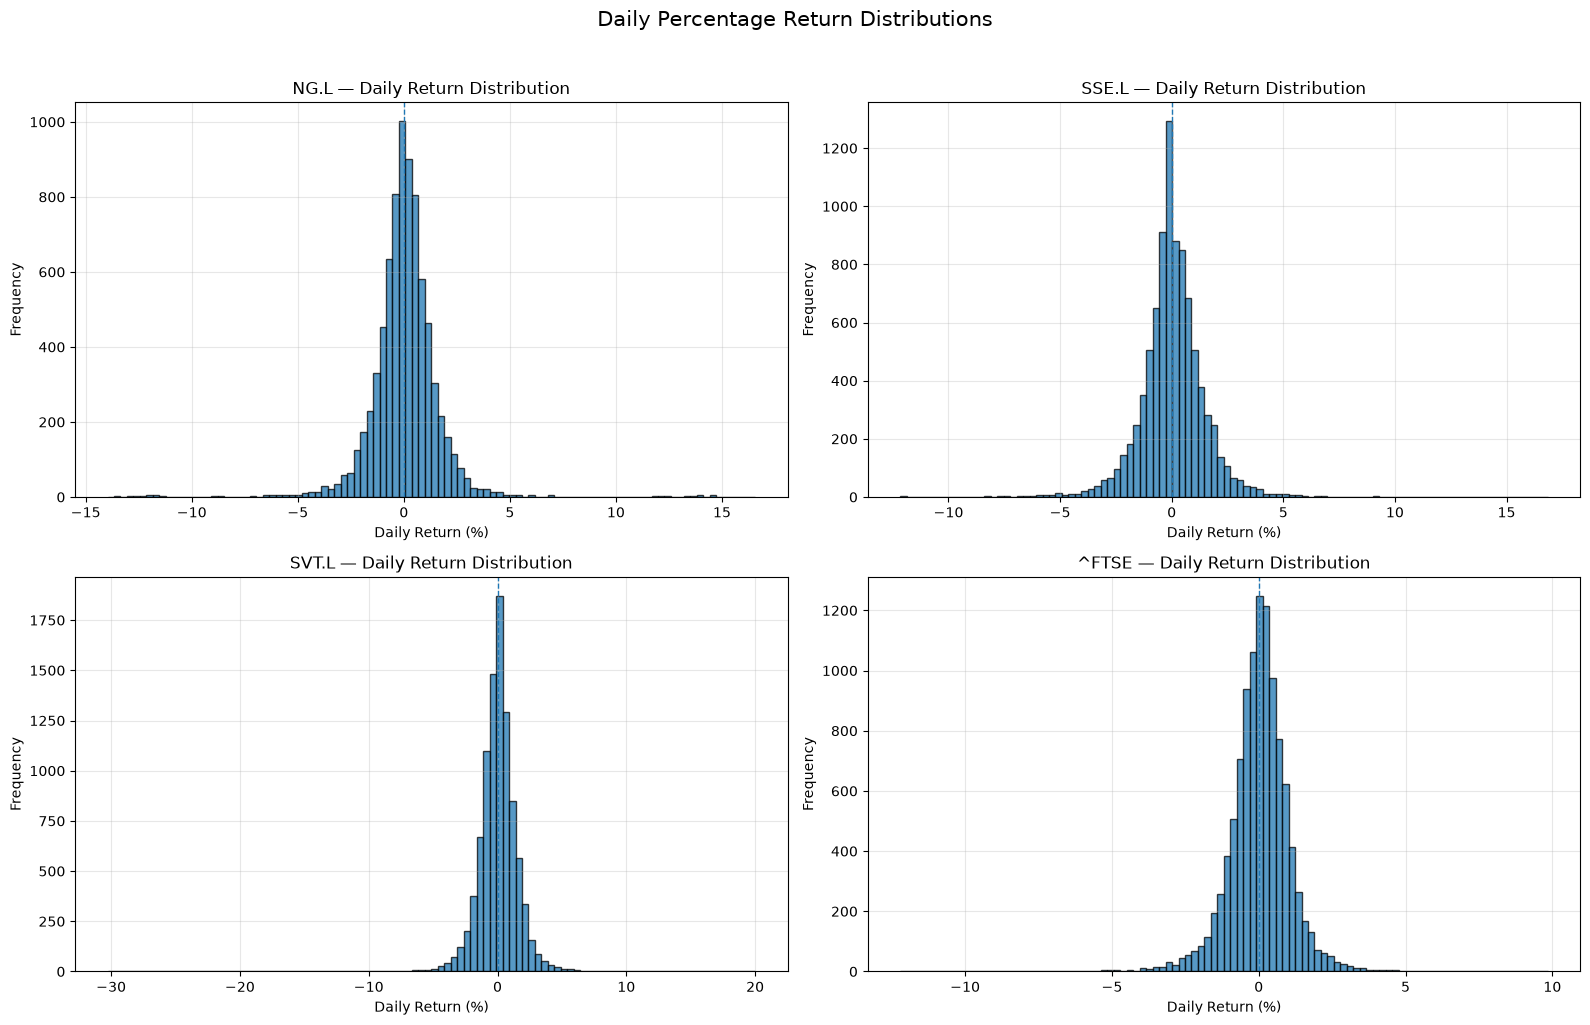

In [18]:
# Create a 2x2 layout to examine the daily return distributions
# of the four financial instruments.

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(16, 10)
)

# Define the instruments to be analysed.
tickers = ["NG.L", "SSE.L", "SVT.L", "^FTSE"]

# Generate one histogram for each instrument.
for ticker, ax in zip(tickers, axes.flatten()):

    # Retrieve valid daily percentage returns.
    # Missing observations are excluded from the histogram only.
    returns = daily_returns[ticker].dropna()

    # Plot the complete return distribution.
    # All valid observations are retained, including extreme values.
    ax.hist(
        returns,
        bins=100,
        edgecolor="black",
        alpha=0.75
    )

    # Add chart title and axis labels.
    ax.set_title(
        f"{ticker} — Daily Return Distribution"
    )

    ax.set_xlabel("Daily Return (%)")
    ax.set_ylabel("Frequency")

    # Add a vertical reference line at zero return.
    ax.axvline(
        x=0,
        linestyle="--",
        linewidth=1
    )

    # Improve chart readability.
    ax.grid(
        True,
        alpha=0.3
    )


# Add an overall figure title.
fig.suptitle(
    "Daily Percentage Return Distributions",
    fontsize=15,
    y=1.02
)

# Adjust spacing and display the charts.
plt.tight_layout()
plt.show()

### 3.6 Descriptive Statistics of Daily Returns

This section examines the statistical characteristics of daily percentage returns for the four financial instruments.

The following statistical measures will be calculated:

- Mean and median daily returns.
- Standard deviation of daily returns.
- Minimum and maximum daily returns.
- Skewness.
- Excess kurtosis.

These measures provide information about the central tendency, dispersion, asymmetry and tail characteristics of each return distribution.

**Methodological considerations:**

- Standard deviation is calculated using the sample standard deviation.
- Skewness measures the asymmetry of the return distribution.
- Excess kurtosis measures the tail characteristics relative to a normal distribution, for which the theoretical value is zero.
- Missing observations are excluded from individual statistical calculations.
- All valid return observations are retained, including extreme observations.

The results are descriptive and do not establish future expected returns or investment risk by themselves.

In [24]:
# Calculate descriptive statistics for the daily percentage returns.
# Pandas describe() provides the main distributional statistics,
# while skew() and kurt() provide additional distribution measures.

# Generate the standard descriptive statistics for each instrument.
return_statistics_df = daily_returns_df.describe().T

# Add distribution asymmetry and excess kurtosis.
return_statistics_df["Skewness"] = daily_returns_df.skew()

return_statistics_df["Excess Kurtosis"] = daily_returns_df.kurt()

# Rename the columns to improve readability.
return_statistics_df = return_statistics_df.rename(
    columns={
        "count": "Observations",
        "mean": "Mean (%)",
        "std": "Standard Deviation (%)",
        "min": "Minimum (%)",
        "25%": "25th Percentile (%)",
        "50%": "Median (%)",
        "75%": "75th Percentile (%)",
        "max": "Maximum (%)",
    }
)

# Display the complete descriptive statistics table.
display(
    return_statistics_df.round(4)
)

,Observations,Mean (%),Standard Deviation (%),Minimum (%),25th Percentile (%),Median (%),75th Percentile (%),Maximum (%),Skewness,Excess Kurtosis
NG.L,7888.0,0.0347,1.7495,-13.9683,-0.6534,0.0126,0.7428,16.5617,0.2607,21.4481
SSE.L,9058.0,0.0371,1.4619,-12.1689,-0.6487,0.0000,0.7440,16.8397,0.0355,9.2492
SVT.L,9453.0,0.0349,1.5450,-30.2752,-0.7293,0.0000,0.8003,20.0000,-0.2497,29.8071
^FTSE,10684.0,0.0264,1.0671,-12.2156,-0.4944,0.0585,0.5836,9.8387,-0.3878,9.7750


#### 3.6.1 Interpretation of Daily Return Statistics

The descriptive statistics reveal several differences in the historical daily return behaviour of the four instruments.

**Mean Daily Returns**

All four instruments exhibit positive historical mean daily price returns.

SSE presents the highest mean daily return (0.0371%), followed by Severn Trent (0.0349%), National Grid (0.0347%) and the FTSE 100 (0.0264%).

These historical averages are descriptive measures and should not be interpreted as estimates of future expected returns.

**Return Dispersion**

National Grid exhibits the highest daily standard deviation (1.7495%), followed by Severn Trent (1.5450%) and SSE (1.4619%).

The FTSE 100 has the lowest standard deviation (1.0671%) over its historical sample.

These results indicate differences in the historical dispersion of daily price returns. They do not constitute a complete assessment of investment risk.

**Return Asymmetry**

The skewness results indicate different distributional characteristics:

- National Grid exhibits positive skewness (0.2607).
- SSE exhibits a distribution relatively close to symmetry (0.0355).
- Severn Trent exhibits negative skewness (-0.2497).
- The FTSE 100 exhibits the most negative skewness (-0.3878).

The negative skewness observed in Severn Trent and the FTSE 100 indicates relatively longer or heavier negative tails.

**Excess Kurtosis**

All four instruments exhibit substantial positive excess kurtosis.

Severn Trent presents the highest value (29.8071), followed by National Grid (21.4481), the FTSE 100 (9.7750) and SSE (9.2492).

These results indicate that the historical return distributions exhibit substantially heavier tails than a normal distribution.

### Preliminary Research Implications

The observed asymmetry and excess kurtosis suggest that normality assumptions should not be adopted without further statistical investigation.

Future forecasting and risk modelling should consider the possibility of non-normal return distributions and asymmetric extreme movements.

These findings are preliminary and do not establish future return or risk characteristics.

### 3.7 Historical Volatility Analysis

This section investigates how the historical volatility of the four financial instruments has evolved over time.

Unlike the full-sample standard deviation calculated previously, rolling volatility captures changes in return dispersion across different historical periods.

A 21-observation rolling window will be used to estimate monthly historical volatility.

The rolling standard deviation is calculated as:

\[
\sigma_{21,t} = Std(R_{t-20}, \ldots, R_t)
\]

For comparison purposes, the rolling volatility will also be annualised:

\[
\sigma_{annualised} = \sigma_{21,t} \times \sqrt{252}
\]

Where:

- \(R_t\) represents the daily percentage return.
- 21 represents the rolling observation window.
- 252 represents the conventional number of trading sessions per year.

The resulting volatility estimates are expressed as annualised percentages.

**Methodological considerations:**

- Volatility is calculated independently for each instrument.
- A complete window of 21 valid returns is required.
- Missing observations are not imputed.
- No observations are removed or modified.
- The analysis uses historical price returns rather than total investment returns.

The purpose is to identify historical changes in volatility, periods of elevated market uncertainty and differences in the volatility behaviour of the four instruments.

In [25]:
# Define the rolling window and annualisation factor.
# A 21-observation window represents approximately one trading month.

ROLLING_WINDOW = 21
TRADING_DAYS_PER_YEAR = 252


# Store the rolling volatility series for each instrument.
rolling_volatility = {}

for ticker, returns in daily_returns.items():

    # Calculate the rolling standard deviation of daily returns.
    # A complete window of 21 valid observations is required.
    rolling_std = returns.rolling(
        window=ROLLING_WINDOW,
        min_periods=ROLLING_WINDOW
    ).std()

    # Annualise the rolling standard deviation.
    # Daily returns are expressed in percentage points.
    annualised_volatility = (
        rolling_std * np.sqrt(TRADING_DAYS_PER_YEAR)
    )

    # Store the annualised rolling volatility.
    rolling_volatility[ticker] = annualised_volatility


# Combine the individual volatility series into a DataFrame.
rolling_volatility_df = pd.DataFrame(
    rolling_volatility
)


# Display the first valid observations for each instrument.
display(
    rolling_volatility_df.dropna(how="all").head(10).round(4)
)

,NG.L,SSE.L,SVT.L,^FTSE
Date,,,,
1984-02-01,NaN,NaN,NaN,13.6853
1984-02-02,NaN,NaN,NaN,14.2868
1984-02-03,NaN,NaN,NaN,13.4503
1984-02-06,NaN,NaN,NaN,14.9190
1984-02-07,NaN,NaN,NaN,15.8255
1984-02-08,NaN,NaN,NaN,16.0900
1984-02-09,NaN,NaN,NaN,16.2563
1984-02-10,NaN,NaN,NaN,16.0068
1984-02-13,NaN,NaN,NaN,15.4465


#### 3.7.1 Rolling Volatility Summary

This section provides a statistical summary of the annualised rolling volatility estimates calculated using a 21-observation window.

The analysis examines:

- Number of valid volatility observations.
- Mean and median rolling volatility.
- Standard deviation of rolling volatility.
- Minimum and maximum rolling volatility.

These statistics provide an overview of the historical variability of each instrument's volatility.

The instruments are analysed independently because their historical coverage differs.

The results describe historical volatility estimates and should not be interpreted as forecasts of future market risk.

In [26]:
# Calculate descriptive statistics for the annualised rolling
# volatility series of each instrument.

volatility_statistics = {}

for ticker, volatility in rolling_volatility.items():

    # Exclude missing values from the statistical calculations.
    valid_volatility = volatility.dropna()

    # Calculate the descriptive statistics.
    statistics = {
        "Observations": valid_volatility.count(),
        "Mean (%)": valid_volatility.mean(),
        "Median (%)": valid_volatility.median(),
        "Standard Deviation (%)": valid_volatility.std(),
        "Minimum (%)": valid_volatility.min(),
        "Maximum (%)": valid_volatility.max(),
        "First Valid Date": (
            valid_volatility.index.min().date()
            if not valid_volatility.empty else None
        ),
        "Last Valid Date": (
            valid_volatility.index.max().date()
            if not valid_volatility.empty else None
        ),
    }

    # Store the results for the current instrument.
    volatility_statistics[ticker] = statistics


# Organise the results into a DataFrame.
volatility_statistics_df = pd.DataFrame(
    volatility_statistics
).T


# Display the rolling volatility summary.
display(
    volatility_statistics_df.round(4)
)

,Observations,Mean (%),Median (%),Standard Deviation (%),Minimum (%),Maximum (%),First Valid Date,Last Valid Date
NG.L,7868,22.995874,18.644318,16.216299,5.832929,140.875772,1996-01-09,2026-10-30
SSE.L,9038,20.86706,18.328799,10.390135,5.36813,110.799904,1991-07-16,2026-10-30
SVT.L,9433,22.047745,19.650211,10.874368,8.563593,112.385109,1990-01-09,2026-10-30
^FTSE,8571,15.132178,12.828709,8.761419,4.035105,79.972783,1984-02-01,2026-10-30


#### 3.7.2 Interpretation of Historical Volatility Statistics

The rolling volatility statistics reveal differences in the historical variability of the four instruments.

**National Grid (NG.L)**

National Grid exhibits the highest mean annualised rolling volatility (22.996%) and the highest standard deviation of rolling volatility estimates (16.216%). Its maximum observed rolling volatility reaches 140.876%.

The difference between its mean and median volatility suggests the influence of periods with substantially elevated volatility.

**SSE (SSE.L)**

SSE presents the lowest mean annualised rolling volatility among the three utility companies, at 20.867%. Its median volatility is 18.329%, while its maximum reaches 110.800%.

**Severn Trent (SVT.L)**

Severn Trent presents the highest median annualised rolling volatility (19.650%) among the four instruments. Its mean volatility is 22.048%, with a maximum of 112.385%.

**FTSE 100 (^FTSE)**

The FTSE 100 exhibits the lowest mean and median annualised rolling volatility, at 15.132% and 12.829%, respectively.

This indicates lower historical return dispersion than the individual utility shares over the respective historical samples.

### Comparative Interpretation

The three utility companies exhibit higher mean annualised rolling volatility than the FTSE 100.

National Grid has the highest mean, while Severn Trent has the highest median.

The substantial differences between mean and median volatility, together with the high maximum values, indicate that volatility varied considerably across historical periods.

### Methodological Limitations

The instruments have different historical starting dates. Consequently, their full-sample volatility summaries incorporate different historical market regimes.

Maximum volatility estimates should be interpreted cautiously because they may be influenced by extreme observations already documented during Phase 3.

These findings describe historical volatility and should not be interpreted as forecasts of future risk.

#### 3.7.3 Rolling Volatility Visualisation

This section visualises the historical evolution of annualised rolling volatility for the four financial instruments.

Each instrument will be displayed in a separate chart, preserving its original historical coverage.

The visual analysis aims to identify:

- Periods of elevated volatility.
- Periods of relatively stable volatility.
- Changes in volatility over time.
- Differences in the persistence and magnitude of volatility fluctuations.

A common vertical scale will be used to facilitate visual comparison of volatility magnitudes.

The horizontal axes will retain the individual historical periods of each instrument.

All calculated volatility observations will be preserved. No smoothing, filtering or outlier removal will be applied.

The charts are exploratory and do not establish the causes of historical volatility changes.

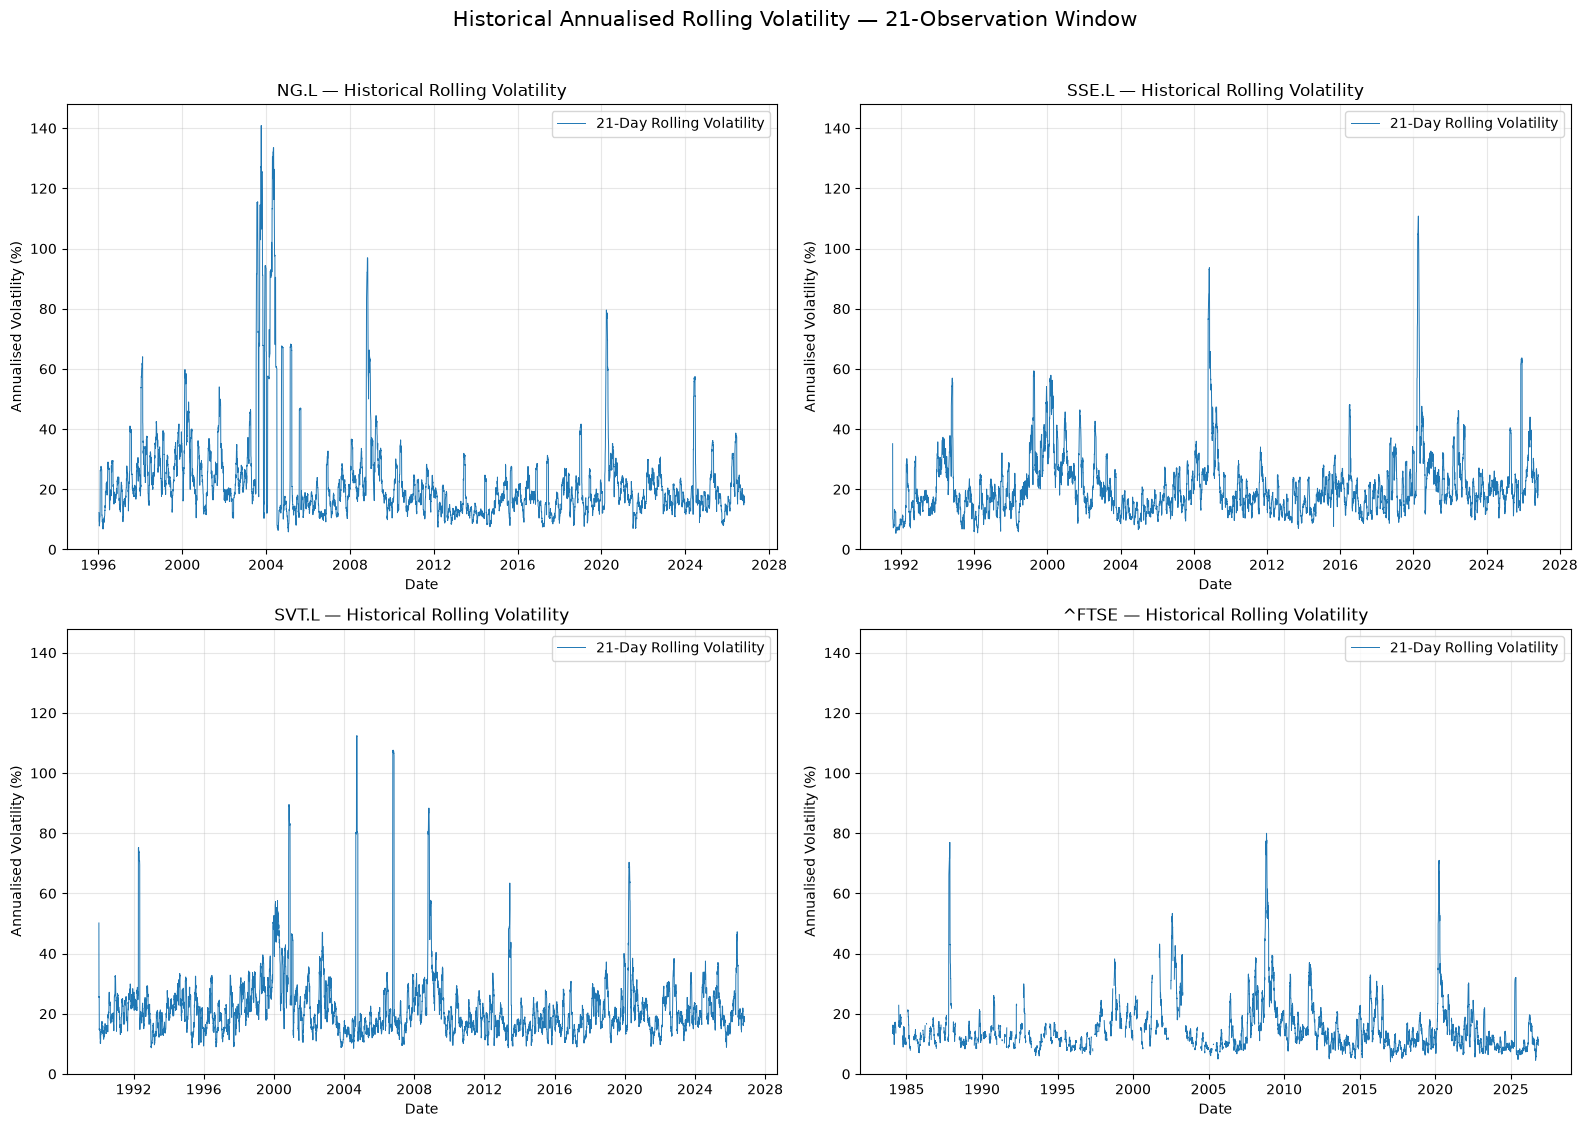

In [27]:
# Create a 2x2 layout to visualise the historical annualised
# rolling volatility of the four financial instruments.

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(16, 11)
)

# Define the instruments and their display order.
tickers = ["NG.L", "SSE.L", "SVT.L", "^FTSE"]

# Determine a common upper limit for the vertical axis.
# This allows visual comparison using the same volatility scale.

common_y_max = rolling_volatility_df.max().max() * 1.05


# Generate one rolling volatility chart for each instrument.
for ticker, ax in zip(tickers, axes.flatten()):

    # Retrieve the annualised rolling volatility series.
    volatility = rolling_volatility[ticker]

    # Plot the historical volatility evolution.
    ax.plot(
        volatility.index,
        volatility,
        linewidth=0.7,
        label="21-Day Rolling Volatility"
    )

    # Add chart title and axis labels.
    ax.set_title(
        f"{ticker} — Historical Rolling Volatility"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Annualised Volatility (%)")

    # Apply the common vertical scale.
    ax.set_ylim(0, common_y_max)

    # Improve chart readability.
    ax.grid(
        True,
        alpha=0.3
    )

    # Display the legend.
    ax.legend()


# Add an overall figure title.
fig.suptitle(
    "Historical Annualised Rolling Volatility — 21-Observation Window",
    fontsize=15,
    y=1.02
)

# Adjust spacing between charts.
plt.tight_layout()

# Display the four volatility charts.
plt.show()

#### 3.7.4 Interpretation of Historical Rolling Volatility

The historical rolling volatility charts reveal substantial variations in the volatility behaviour of the four financial instruments.

**National Grid (NG.L)**

National Grid exhibits the most pronounced volatility peaks among the four instruments. A particularly elevated period is visible between approximately 2002 and 2004, when annualised rolling volatility reaches levels above 140%.

Additional periods of elevated volatility can be observed around 2008–2009 and 2020.

Following 2010, rolling volatility generally remains below the levels observed during the most pronounced earlier episodes.

**SSE (SSE.L)**

SSE displays several periods of elevated volatility, particularly around 1999–2002, 2008–2009 and 2020.

Its volatility fluctuates considerably throughout the historical sample, alternating between periods of relative stability and episodes of increased dispersion.

**Severn Trent (SVT.L)**

Severn Trent exhibits pronounced volatility episodes around 1999–2001 and between approximately 2004 and 2009.

Additional increases are visible around 2014 and 2020.

Outside these periods, volatility generally remains at lower levels, although recurring fluctuations are still present.

**FTSE 100 (^FTSE)**

The FTSE 100 generally exhibits lower rolling volatility than the three individual utility companies.

However, several pronounced volatility episodes are visible, particularly around 1987, 2008–2009 and 2020.

These observations demonstrate that the broader equity market also experienced substantial periods of increased volatility.

### Comparative Findings

The visual analysis supports several preliminary observations:

1. The three utility companies generally exhibit higher rolling volatility than the FTSE 100.
2. Volatility is not constant over time and varies substantially across historical periods.
3. Periods of elevated volatility often appear in clusters rather than as isolated observations.
4. The magnitude and persistence of volatility episodes differ between the individual companies and the market benchmark.
5. Some periods of elevated volatility occur across multiple instruments, suggesting possible exposure to common market conditions.

### Methodological Limitations

The historical samples have different starting dates and therefore cover different market environments.

The 21-observation rolling window is sensitive to individual daily return observations. Consequently, short-lived increases in volatility can produce pronounced peaks.

The charts do not establish the economic causes of these episodes. Their interpretation should remain descriptive.

Furthermore, the annualised rolling volatility estimates are historical measures and should not be interpreted as forecasts of future volatility.

## 3.8 Comparative Return and Volatility Analysis

This section brings together the daily return and rolling volatility analyses to provide a comparative view of the historical behaviour of the four financial instruments.

The previous sections examined daily return distributions and the evolution of annualised rolling volatility independently.

This section investigates their relationship from a descriptive perspective.

The analysis will focus on:

- Differences in daily return dispersion across instruments.
- The relationship between the magnitude of daily returns and prevailing volatility levels.
- Whether larger absolute daily returns tend to occur during periods of elevated rolling volatility.
- Differences in the observed return and volatility behaviour between individual utility companies and the FTSE 100 benchmark.

Daily returns will be compared with the corresponding annualised rolling volatility estimates.

Only observations for which both measures are available will be included in the comparative analysis.

No missing values will be imputed, and no observations will be removed on the basis of their magnitude.

The analysis is descriptive. It does not establish causality, predict future volatility or imply that elevated volatility necessarily produces negative returns.

#### 3.8.1 Return and Volatility Data Alignment

Before conducting the comparative analysis, the daily return and rolling volatility series must be aligned by their observation dates.

For each instrument, the following variables will be combined:

- Daily percentage return.
- Absolute daily percentage return.
- Annualised 21-observation rolling volatility.

The absolute daily return represents the magnitude of the daily price movement, regardless of its direction.

Only dates with valid observations for all three variables will be retained in the resulting analytical datasets.

This operation does not modify the original market data or the previously calculated return and volatility series.

The resulting datasets will provide a consistent basis for the subsequent comparative analysis.

In [28]:
# Create aligned datasets combining daily returns and rolling volatility.
# All variables must refer to the same observation dates.

comparative_data = {}

for ticker in daily_returns_df.columns:

    # Combine the daily return, its absolute magnitude,
    # and the corresponding annualised rolling volatility.
    aligned_df = pd.DataFrame({
        "Daily Return (%)": daily_returns_df[ticker],
        "Absolute Daily Return (%)": daily_returns_df[ticker].abs(),
        "Annualised Rolling Volatility (%)": rolling_volatility_df[ticker]
    })

    # Retain only observations where all three variables are available.
    # This affects only the new analytical dataset.
    aligned_df = aligned_df.dropna()

    # Store the aligned dataset for each instrument.
    comparative_data[ticker] = aligned_df


# Generate a summary of the aligned datasets.
alignment_summary = {}

for ticker, df in comparative_data.items():

    alignment_summary[ticker] = {
        "Valid Observations": len(df),
        "First Observation": df.index.min().date(),
        "Last Observation": df.index.max().date()
    }


# Convert the summary into a DataFrame for display.
alignment_summary_df = pd.DataFrame(
    alignment_summary
).T

display(alignment_summary_df)

,Valid Observations,First Observation,Last Observation
NG.L,7868,1996-01-09,2026-10-30
SSE.L,9038,1991-07-16,2026-10-30
SVT.L,9433,1990-01-09,2026-10-30
^FTSE,8571,1984-02-01,2026-10-30


#### 3.8.2 Absolute Daily Returns versus Previous Volatility

This section investigates the relationship between the magnitude of daily price movements and the volatility prevailing before each observation.

A scatter plot will be used to compare:

- Absolute daily percentage returns.
- Annualised rolling volatility estimated using information available up to the previous observation.

The volatility series is shifted by one observation to ensure that the explanatory volatility measure does not incorporate the daily return being examined.

This temporal alignment reduces the mechanical relationship that would arise if the current daily return were included in its corresponding rolling volatility estimate.

The analysis will examine whether larger daily price movements tend to occur following periods of elevated historical volatility.

Each instrument will be analysed independently.

The results are descriptive and do not establish causality or demonstrate predictive relationships.

In [29]:
# Create datasets using previous-observation volatility.
# This prevents the current daily return from being included
# in the volatility measure used for comparison.

lagged_volatility_data = {}

for ticker in daily_returns_df.columns:

    # Retrieve the daily return and its absolute magnitude.
    daily_return = daily_returns_df[ticker]

    absolute_return = daily_return.abs()

    # Shift rolling volatility by one observation.
    # The volatility value for date t therefore represents
    # information available up to the previous observation.
    previous_volatility = rolling_volatility_df[ticker].shift(1)

    # Combine the variables into one analytical DataFrame.
    aligned_df = pd.DataFrame({
        "Daily Return (%)": daily_return,
        "Absolute Daily Return (%)": absolute_return,
        "Previous Annualised Volatility (%)": previous_volatility
    })

    # Retain only observations with all required variables.
    aligned_df = aligned_df.dropna()

    # Store the resulting dataset.
    lagged_volatility_data[ticker] = aligned_df


# Summarise the number and temporal coverage of valid observations.
lagged_alignment_summary = {}

for ticker, df in lagged_volatility_data.items():

    lagged_alignment_summary[ticker] = {
        "Valid Observations": len(df),
        "First Observation": df.index.min().date(),
        "Last Observation": df.index.max().date()
    }


# Display the alignment summary.
lagged_alignment_summary_df = pd.DataFrame(
    lagged_alignment_summary
).T

display(lagged_alignment_summary_df)

,Valid Observations,First Observation,Last Observation
NG.L,7867,1996-01-10,2026-10-30
SSE.L,9037,1991-07-17,2026-10-30
SVT.L,9432,1990-01-10,2026-10-30
^FTSE,8495,1984-02-02,2026-10-30


In [30]:
# Calculate the correlation between absolute daily returns
# and previous-observation annualised rolling volatility.

correlation_results = {}

for ticker, df in lagged_volatility_data.items():

    correlation = df[
        "Absolute Daily Return (%)"
    ].corr(
        df["Previous Annualised Volatility (%)"]
    )

    correlation_results[ticker] = correlation


# Display the correlation results.
correlation_df = pd.DataFrame.from_dict(
    correlation_results,
    orient="index",
    columns=["Absolute Return vs Previous Volatility Correlation"]
)

display(correlation_df.round(4))

,Absolute Return vs Previous Volatility Correlation
NG.L,0.3030
SSE.L,0.3212
SVT.L,0.1906
^FTSE,0.4319


#### 3.8.3 Comparative Findings

The correlation analysis identifies positive relationships between previous annualised rolling volatility and the magnitude of subsequent daily price returns across all four instruments.

The FTSE 100 exhibits the strongest correlation (0.4319), followed by SSE (0.3212), National Grid (0.3030) and Severn Trent (0.1906).

These findings suggest that periods of elevated historical volatility tend to be associated with larger subsequent daily price movements.

However, the observed correlations are not evidence of causality or predictive performance.

### Conclusion

Historical volatility contains relevant descriptive information about the subsequent magnitude of daily price movements.

The strength of this relationship differs across instruments and should be investigated further only if justified during the modelling and validation phases.

## 4. Research Summary and Conclusions

### 4.1 Main Research Findings

The exploratory analysis identified several relevant characteristics of the historical behaviour of the four financial instruments.

**Historical Price Behaviour**

All four instruments exhibit an overall upward long-term price trajectory, although their historical paths differ considerably.

**Daily Returns**

The descriptive statistics reveal differences in return dispersion and distributional characteristics.

The three utility companies exhibit higher historical daily return standard deviations than the FTSE 100 over their respective samples.

All four instruments display substantial positive excess kurtosis, indicating heavier return tails than those of a normal distribution.

**Historical Volatility**

The rolling volatility analysis indicates that volatility varies considerably over time.

The three utility companies exhibit higher mean annualised rolling volatility than the FTSE 100.

Periods of elevated volatility are often clustered, although their magnitude and persistence differ across instruments.

**Return and Volatility Relationship**

The correlation analysis identifies positive relationships between previous annualised rolling volatility and subsequent absolute daily returns across all four instruments.

The FTSE 100 exhibits the strongest correlation (0.4319), while Severn Trent presents the weakest (0.1906).

These relationships are descriptive and do not establish causality or predictive performance.

### 4.2 Methodological Limitations

The analysis has several limitations:

- Historical samples have different starting dates.
- Daily returns are calculated using closing prices and exclude dividends.
- Historical price and corporate action limitations identified during Phase 3 remain unresolved.
- Macroeconomic and cross-asset variables have not yet been incorporated.
- Historical descriptive statistics do not establish future market behaviour.
- The analysis does not evaluate forecasting performance or trading profitability.

These limitations must be considered in subsequent research phases.

### 4.3 Conclusion

The exploratory analysis establishes an initial understanding of the historical price behaviour, daily return distributions and volatility characteristics of the selected instruments.

The findings indicate that the three utility companies exhibit distinct historical behaviours and generally higher volatility than the FTSE 100.

The results also highlight the importance of considering non-normal return distributions and time-varying volatility in subsequent modelling research.

No forecasting or trading conclusions are drawn at this stage.

### 